In [1]:
import os
import ee
import geemap
import pandas as pd
from dotenv import load_dotenv

load_dotenv()
ee.Initialize(project=os.getenv("EE_PROJECT"))

# Rough Accra study area (we'll replace it with official boundaries later)
accra = ee.Geometry.Rectangle([-0.35, 5.45, 0.05, 5.80])


def mask_clouds(image):
    """Remove cloud, cirrus, dilated cloud and cloud shadow pixels."""
    qa = image.select("QA_PIXEL")
    bad = (qa.bitwiseAnd(1 << 1).neq(0)
           .Or(qa.bitwiseAnd(1 << 2).neq(0))
           .Or(qa.bitwiseAnd(1 << 3).neq(0))
           .Or(qa.bitwiseAnd(1 << 4).neq(0)))
    return image.updateMask(bad.Not())


def get_landsat(start, end, max_cloud=70):
    """Landsat 8 + 9 Level-2 images over Accra, cloud-masked."""
    l8 = ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
    l9 = ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
    return (l8.merge(l9)
            .filterBounds(accra)
            .filterDate(start, end)
            .filter(ee.Filter.lt("CLOUD_COVER", max_cloud))
            .map(mask_clouds))


dry_2023 = get_landsat("2022-12-01", "2023-03-01")
print("Dry season 2022/23 scenes:", dry_2023.size().getInfo())

Dry season 2022/23 scenes: 11


In [2]:
def add_lst(image):
    """Convert the thermal band to Land Surface Temperature in Celsius."""
    lst = (image.select("ST_B10")
           .multiply(0.00341802)
           .add(149.0)
           .subtract(273.15)
           .rename("LST"))
    return image.addBands(lst)


# Add LST to every image, then combine the dry-season photos into one
lst_collection = dry_2023.map(add_lst)
lst_dry_2023 = lst_collection.select("LST").median().clip(accra)

# Show it on a map
m = geemap.Map(center=[5.6, -0.15], zoom=10)
vis = {"min": 25, "max": 45,
       "palette": ["blue", "cyan", "green", "yellow", "orange", "red"]}
m.addLayer(lst_dry_2023, vis, "LST dry season 2022/23 (°C)")
m.add_colorbar(vis, label="LST (°C)")
m

Map(center=[5.6, -0.15], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', …

In [3]:
stats = lst_dry_2023.reduceRegion(
    reducer=ee.Reducer.minMax()
        .combine(ee.Reducer.mean(), sharedInputs=True)
        .combine(ee.Reducer.percentile([5, 50, 95]), sharedInputs=True),
    geometry=accra,
    scale=100,
    maxPixels=1e9
).getInfo()

for key, value in stats.items():
    print(f"{key}: {value:.1f}")

LST_max: 51.3
LST_mean: 34.5
LST_min: 26.4
LST_p5: 27.4
LST_p50: 36.2
LST_p95: 41.7


In [4]:
def add_indices(image):
    """Scale reflectance bands, then add NDVI and NDBI."""
    sr = image.select("SR_B.").multiply(0.0000275).add(-0.2)
    ndvi = sr.normalizedDifference(["SR_B5", "SR_B4"]).rename("NDVI")
    ndbi = sr.normalizedDifference(["SR_B6", "SR_B5"]).rename("NDBI")
    return image.addBands([ndvi, ndbi])


indices_dry_2023 = (dry_2023.map(add_indices)
                    .select(["NDVI", "NDBI"])
                    .median()
                    .clip(accra))

m = geemap.Map(center=[5.6, -0.15], zoom=10)
ndvi_vis = {"min": 0, "max": 0.8,
            "palette": ["brown", "yellow", "lightgreen", "darkgreen"]}
ndbi_vis = {"min": -0.3, "max": 0.3,
            "palette": ["green", "white", "gray", "red"]}
m.addLayer(indices_dry_2023.select("NDVI"), ndvi_vis, "NDVI dry 2022/23")
m.addLayer(indices_dry_2023.select("NDBI"), ndbi_vis, "NDBI dry 2022/23")
m.addLayer(lst_dry_2023, {"min": 25, "max": 45,
           "palette": ["blue", "cyan", "green", "yellow", "orange", "red"]},
           "LST dry 2022/23")
m

Map(center=[5.6, -0.15], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', …

Pixels sampled: 1022
       LST  NDVI  NDBI
LST   1.00 -0.78  0.74
NDVI -0.78  1.00 -0.91
NDBI  0.74 -0.91  1.00


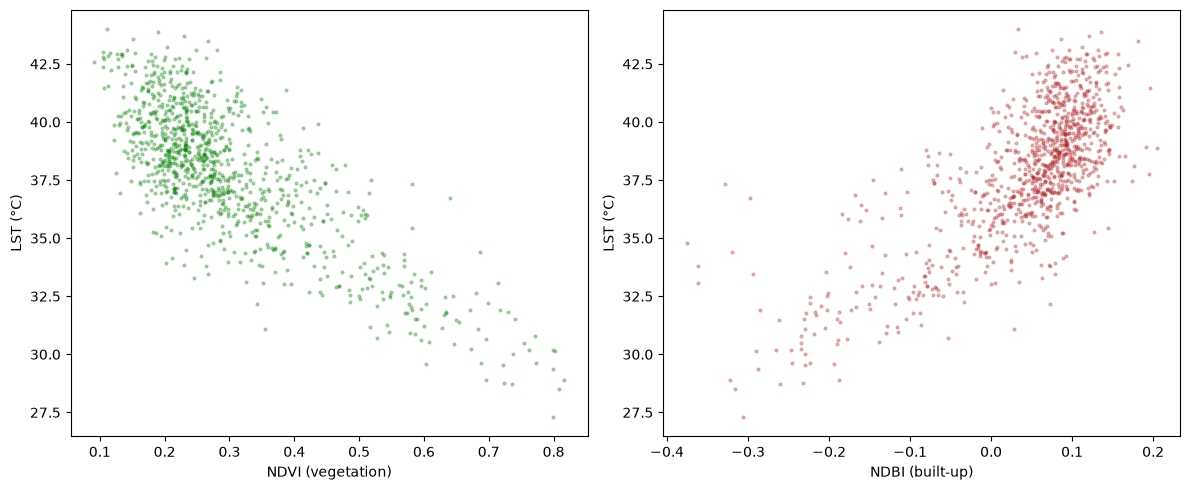

In [7]:
import matplotlib.pyplot as plt

# 1. Water mask: drop pixels that are water more than half of the time
water = (ee.Image("JRC/GSW1_4/GlobalSurfaceWater")
         .select("occurrence").unmask(0).gt(50))

# 2. Stack LST, NDVI and NDBI into one image, with water removed
combined = (lst_dry_2023.addBands(indices_dry_2023)
            .updateMask(water.Not()))

# 3. Take 5,000 random sample pixels and bring them into a table
samples = combined.sample(
    region=accra,
    scale=200,
    numPixels=1500,
    seed=42,
    tileScale=4
)
features = samples.getInfo()["features"]
df = pd.DataFrame([f["properties"] for f in features]).dropna()

print("Pixels sampled:", len(df))
print(df[["LST", "NDVI", "NDBI"]].corr().round(2))

# 4. Scatter plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(df["NDVI"], df["LST"], s=4, alpha=0.3, color="green")
axes[0].set_xlabel("NDVI (vegetation)")
axes[0].set_ylabel("LST (°C)")
axes[1].scatter(df["NDBI"], df["LST"], s=4, alpha=0.3, color="firebrick")
axes[1].set_xlabel("NDBI (built-up)")
axes[1].set_ylabel("LST (°C)")
plt.tight_layout()
plt.show()

In [8]:
districts = (ee.FeatureCollection("WM/geoLab/geoBoundaries/600/ADM2")
             .filter(ee.Filter.eq("shapeGroup", "GHA")))

print("Ghana districts in the dataset:", districts.size().getInfo())

# Keep only the districts that touch our rough Accra box
accra_districts = districts.filterBounds(accra)
names = sorted(accra_districts.aggregate_array("shapeName").getInfo())

print("Districts touching our study box:", len(names))
for n in names:
    print("-", n)

Ghana districts in the dataset: 260
Districts touching our study box: 28
- Ablekuma Central Municipal
- Ablekuma North Municipal
- Ablekuma West Municipal
- Accra Metropolis
- Adenta Municipal
- Akwapem South
- Ashaiman Municipal
- Ayawaso Central Municipal
- Ayawaso East Municipal
- Ayawaso North Municipal
- Ayawaso West
- Ga Central Municipal
- Ga East
- Ga North Municipal
- Ga South Municipal
- Ga West Municipal
- Korle Klottey Municipal
- Kpone Katamanso
- Krowor Municipal
- La Dade-kotopon
- La-nkwantanang-madina
- Ledzokuku Municipal
- Ningo/prampram
- Nsawam Adoagyiri
- Okaikwei North Municipal
- Tema Metropolitan
- Tema West Municipal
- Weija Gbawe Municipal


In [9]:
m = geemap.Map(center=[5.6, -0.15], zoom=10)

lst_vis = {"min": 25, "max": 45,
           "palette": ["blue", "cyan", "green", "yellow", "orange", "red"]}
m.addLayer(lst_dry_2023, lst_vis, "LST dry 2022/23")

# Draw district outlines only (no fill)
outline = accra_districts.style(color="black", fillColor="00000000", width=1.5)
m.addLayer(outline, {}, "District boundaries")

m.addLayer(accra, {"color": "red"}, "Study box")
m

Map(center=[5.6, -0.15], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', …

In [10]:
# Drop the two Eastern Region districts
exclude = ["Akwapem South", "Nsawam Adoagyiri"]
study_districts = accra_districts.filter(
    ee.Filter.inList("shapeName", exclude).Not()
)
print("Districts kept:", study_districts.size().getInfo())

# LST with water removed, so lagoons and sea don't cool the averages
lst_land = lst_dry_2023.updateMask(water.Not())

# Average LST (and pixel count) inside each district
ranked = lst_land.reduceRegions(
    collection=study_districts,
    reducer=ee.Reducer.mean().combine(ee.Reducer.count(), sharedInputs=True),
    scale=120,
    tileScale=4
)

rows = [f["properties"] for f in ranked.getInfo()["features"]]
ranking = (pd.DataFrame(rows)[["shapeName", "mean", "count"]]
           .rename(columns={"shapeName": "district", "mean": "mean_LST_C",
                            "count": "pixels"})
           .sort_values("mean_LST_C", ascending=False)
           .round(1)
           .reset_index(drop=True))

ranking.index += 1
print(ranking.to_string())

Districts kept: 26
                      district  mean_LST_C  pixels
1             Accra Metropolis        41.9     422
2      Ablekuma West Municipal        40.9     939
3    Ayawaso Central Municipal        40.8     138
4            Tema Metropolitan        40.8    3052
5             Krowor Municipal        40.7    1372
6           Ashaiman Municipal        40.5    1368
7   Ablekuma Central Municipal        40.3    1068
8          Tema West Municipal        40.1    3326
9          Ledzokuku Municipal        39.9    2136
10              Ningo/prampram        39.9    4548
11     Korle Klottey Municipal        39.4     734
12             Kpone Katamanso        39.4   12155
13             La Dade-kotopon        39.0    2605
14    Ablekuma North Municipal        38.3    2202
15      Ayawaso East Municipal        38.3     488
16     Ayawaso North Municipal        38.2     405
17            Adenta Municipal        38.0    5692
18        Ga Central Municipal        37.6    3351
19       La-

In [11]:
# LST for the whole image footprint: no clip to our rough box
lst_full = (lst_collection.select("LST")
            .median()
            .updateMask(water.Not()))

ranked = lst_full.reduceRegions(
    collection=study_districts,
    reducer=ee.Reducer.mean().combine(ee.Reducer.count(), sharedInputs=True),
    scale=120,
    tileScale=4
)

rows = [f["properties"] for f in ranked.getInfo()["features"]]
ranking = (pd.DataFrame(rows)[["shapeName", "mean", "count"]]
           .rename(columns={"shapeName": "district", "mean": "mean_LST_C",
                            "count": "pixels"})
           .sort_values("mean_LST_C", ascending=False)
           .round(1)
           .reset_index(drop=True))

ranking.index += 1
print(ranking.to_string())

                      district  mean_LST_C  pixels
1             Accra Metropolis        41.9     422
2               Ningo/prampram        41.2   43538
3      Ablekuma West Municipal        40.9     939
4    Ayawaso Central Municipal        40.8     138
5            Tema Metropolitan        40.8    3052
6             Krowor Municipal        40.7    1372
7           Ashaiman Municipal        40.5    1368
8   Ablekuma Central Municipal        40.3    1068
9          Tema West Municipal        40.1    3326
10         Ledzokuku Municipal        39.9    2136
11     Korle Klottey Municipal        39.4     734
12             La Dade-kotopon        39.0    2605
13             Kpone Katamanso        38.5   17144
14    Ablekuma North Municipal        38.3    2202
15      Ayawaso East Municipal        38.3     488
16     Ayawaso North Municipal        38.2     405
17            Adenta Municipal        38.0    5692
18        Ga Central Municipal        37.5    3503
19                     Ga East 

In [12]:
# NDVI and NDBI for the full scene (no clip), water removed
indices_full = (dry_2023.map(add_indices)
                .select(["NDVI", "NDBI"])
                .median()
                .updateMask(water.Not()))

stack = lst_full.addBands(indices_full)

ranked = stack.reduceRegions(
    collection=study_districts,
    reducer=ee.Reducer.mean().combine(ee.Reducer.count(), sharedInputs=True),
    scale=120,
    tileScale=4
)

rows = [f["properties"] for f in ranked.getInfo()["features"]]
ranking = (pd.DataFrame(rows)[["shapeName", "LST_mean", "NDVI_mean", "NDBI_mean", "LST_count"]]
           .rename(columns={"shapeName": "district", "LST_mean": "LST_C",
                            "NDVI_mean": "NDVI", "NDBI_mean": "NDBI",
                            "LST_count": "pixels"})
           .sort_values("LST_C", ascending=False)
           .round(2)
           .reset_index(drop=True))

ranking.index += 1
print(ranking.to_string())

# Save a small table for the repo
ranking.to_csv("../reports/district_ranking_dry_2022_23.csv", index_label="rank")

                      district  LST_C  NDVI  NDBI  pixels
1             Accra Metropolis  41.90  0.16  0.10     422
2               Ningo/prampram  41.18  0.28  0.10   43538
3      Ablekuma West Municipal  40.95  0.20  0.11     939
4    Ayawaso Central Municipal  40.80  0.15  0.12     138
5            Tema Metropolitan  40.78  0.27  0.03    3052
6             Krowor Municipal  40.71  0.22  0.09    1372
7           Ashaiman Municipal  40.50  0.22  0.09    1368
8   Ablekuma Central Municipal  40.28  0.18  0.11    1068
9          Tema West Municipal  40.07  0.24  0.06    3326
10         Ledzokuku Municipal  39.92  0.23  0.09    2136
11     Korle Klottey Municipal  39.42  0.26  0.04     734
12             La Dade-kotopon  38.96  0.29  0.04    2605
13             Kpone Katamanso  38.49  0.31  0.06   17144
14    Ablekuma North Municipal  38.33  0.18  0.10    2202
15      Ayawaso East Municipal  38.27  0.26  0.04     488
16     Ayawaso North Municipal  38.17  0.19  0.09     405
17            

In [13]:
def season_ranking(start, end, label):
    """District-level mean LST, NDVI and NDBI for one season."""
    col = get_landsat(start, end)
    n_scenes = col.size().getInfo()

    stack = (col.map(add_lst)
                .map(add_indices)
                .select(["LST", "NDVI", "NDBI"])
                .median()
                .updateMask(water.Not()))

    ranked = stack.reduceRegions(
        collection=study_districts,
        reducer=ee.Reducer.mean().combine(ee.Reducer.count(), sharedInputs=True),
        scale=120,
        tileScale=4
    )

    rows = [f["properties"] for f in ranked.getInfo()["features"]]
    df = (pd.DataFrame(rows)[["shapeName", "LST_mean", "NDVI_mean", "NDBI_mean", "LST_count"]]
          .rename(columns={"shapeName": "district", "LST_mean": "LST_C",
                           "NDVI_mean": "NDVI", "NDBI_mean": "NDBI",
                           "LST_count": "pixels"}))
    df["season"] = label
    df["scenes"] = n_scenes
    return df


# Test on the season we already know
test = season_ranking("2022-12-01", "2023-03-01", "2022/23")
print("Scenes used:", test["scenes"].iloc[0])
print(test.sort_values("LST_C", ascending=False).head(5).round(2).to_string(index=False))

Scenes used: 11
                 district  LST_C  NDVI  NDBI  pixels  season  scenes
         Accra Metropolis  41.90  0.16  0.10     422 2022/23      11
           Ningo/prampram  41.18  0.28  0.10   43538 2022/23      11
  Ablekuma West Municipal  40.95  0.20  0.11     939 2022/23      11
Ayawaso Central Municipal  40.80  0.15  0.12     138 2022/23      11
        Tema Metropolitan  40.78  0.27  0.03    3052 2022/23      11


In [14]:
seasons = [
    ("2019-12-01", "2020-03-01", "2019/20"),
    ("2020-12-01", "2021-03-01", "2020/21"),
    ("2021-12-01", "2022-03-01", "2021/22"),
    ("2022-12-01", "2023-03-01", "2022/23"),
    ("2023-12-01", "2024-03-01", "2023/24"),
]

results = []
for start, end, label in seasons:
    print("Running", label, "...")
    results.append(season_ranking(start, end, label))

all_seasons = pd.concat(results, ignore_index=True)

# Scene counts per season
print()
print(all_seasons.groupby("season")["scenes"].first())

# District mean LST, one column per season
lst_table = (all_seasons.pivot(index="district", columns="season", values="LST_C")
             .round(1)
             .sort_values("2022/23", ascending=False))
print()
print(lst_table.to_string())

all_seasons.round(3).to_csv("../reports/district_ranking_all_seasons.csv", index=False)

Running 2019/20 ...
Running 2020/21 ...
Running 2021/22 ...
Running 2022/23 ...
Running 2023/24 ...

season
2019/20     6
2020/21     6
2021/22     9
2022/23    11
2023/24    11
Name: scenes, dtype: int64

season                      2019/20  2020/21  2021/22  2022/23  2023/24
district                                                               
Accra Metropolis               40.2     43.4     39.2     41.9     40.2
Ningo/prampram                 40.7     42.9     39.9     41.2     41.2
Ablekuma West Municipal        40.4     43.4     39.0     40.9     40.9
Ayawaso Central Municipal      39.7     44.9     39.0     40.8     40.4
Tema Metropolitan              40.0     43.9     38.4     40.8     39.8
Krowor Municipal               39.2     44.3     38.1     40.7     40.8
Ashaiman Municipal             40.4     44.4     39.1     40.5     41.3
Ablekuma Central Municipal     40.4     44.3     39.5     40.3     40.5
Tema West Municipal            39.3     44.2     38.0     40.1     40.0
Le

In [15]:
# Each season's average across districts (a simple, unweighted city average)
city_mean = lst_table.mean()

# How far each district is above or below that season's average
anomaly = (lst_table - city_mean).round(2)
anomaly["avg_anomaly"] = anomaly.mean(axis=1).round(2)
anomaly = anomaly.sort_values("avg_anomaly", ascending=False)
print("Heat relative to the city average (°C):")
print(anomaly.to_string())

# Rank in each season (1 = hottest)
ranks = lst_table.rank(ascending=False).astype(int)
ranks["avg_rank"] = ranks.mean(axis=1).round(1)
ranks["best"] = ranks.drop(columns="avg_rank").min(axis=1)
ranks["worst"] = ranks.drop(columns=["avg_rank", "best"]).max(axis=1)
ranks = ranks.sort_values("avg_rank")
print()
print("Rank by season (1 = hottest):")
print(ranks.to_string())

anomaly.to_csv("../reports/district_anomaly_by_season.csv")

Heat relative to the city average (°C):
season                      2019/20  2020/21  2021/22  2022/23  2023/24  avg_anomaly
district                                                                            
Ningo/prampram                 1.98     0.79     2.44     2.66     1.75         1.92
Ashaiman Municipal             1.68     2.29     1.64     1.96     1.85         1.88
Ablekuma Central Municipal     1.68     2.19     2.04     1.76     1.05         1.74
Accra Metropolis               1.48     1.29     1.74     3.36     0.75         1.72
Ayawaso Central Municipal      0.98     2.79     1.54     2.26     0.95         1.70
Ablekuma West Municipal        1.68     1.29     1.54     2.36     1.45         1.66
Krowor Municipal               0.48     2.19     0.64     2.16     1.35         1.36
Tema Metropolitan              1.28     1.79     0.94     2.26     0.35         1.32
Tema West Municipal            0.58     2.09     0.54     1.56     0.55         1.06
Ledzokuku Municipal      

In [16]:
from ipyleaflet import Marker, DivIcon, LayerGroup

season_cols = ["2019/20", "2020/21", "2021/22", "2022/23", "2023/24"]
anom = anomaly[season_cols]             # heat vs city average, per season
avg_anom = anomaly["avg_anomaly"]       # average across all five seasons

vis = {"min": -4, "max": 4,
       "palette": ["#2166ac", "#67a9cf", "#f7f7f7", "#fddbc7", "#ef8a62", "#b2182b"]}


def district_layer(series):
    """Paint every district with its value from a pandas Series (index = district name)."""
    values = ee.Dictionary(series.to_dict())
    fc = study_districts.map(lambda f: f.set("value", values.get(f.get("shapeName"))))
    return ee.Image().float().paint(fc, "value")


m = geemap.Map(center=[5.68, -0.12], zoom=10)

# 1. Average across all seasons (visible), then one layer per season (hidden)
m.addLayer(district_layer(avg_anom), vis, "Average of all seasons")
for col in season_cols:
    m.addLayer(district_layer(anom[col]), vis, f"Dry season {col}", False)

# 2. District outlines
outline = study_districts.style(color="black", fillColor="00000000", width=1)
m.addLayer(outline, {}, "District outlines")

# 3. Text labels at each district's centre: name + average anomaly
centroids = study_districts.map(
    lambda f: f.setGeometry(f.geometry().centroid(100))
).getInfo()["features"]

markers = []
for f in centroids:
    name = f["properties"]["shapeName"]
    lon, lat = f["geometry"]["coordinates"]
    short = (name.replace(" Municipal", "").replace(" Metropolitan", "")
                 .replace(" Metropolis", ""))
    value = avg_anom.get(name, float("nan"))
    html = (f'<div style="font-size:10px;font-weight:bold;color:black;'
            f'text-shadow:1px 1px 2px white;text-align:center;width:110px;">'
            f'{short}<br>{value:+.1f}°C</div>')
    markers.append(Marker(location=(lat, lon),
                          icon=DivIcon(html=html, icon_size=(110, 28), icon_anchor=(55, 14)),
                          draggable=False))

m.add(LayerGroup(layers=markers, name="District labels"))
m.add_colorbar(vis, label="Heat vs city average (°C)")
m

Map(center=[5.68, -0.12], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

In [17]:
import geopandas as gpd

# 1. Download the district shapes, simplified so the file stays small
simple = study_districts.map(lambda f: f.simplify(maxError=50))
gdf = gpd.GeoDataFrame.from_features(simple.getInfo()["features"], crs="EPSG:4326")
gdf = gdf[["shapeName", "geometry"]].rename(columns={"shapeName": "district"})


# 2. Tidy the results tables (column names without "/" so they are easy to use)
def tidy(df, prefix):
    out = df[season_cols].copy()
    out.columns = [f"{prefix}_{c.replace('/', '_')}" for c in season_cols]
    return out


summary = pd.concat([
    tidy(lst_table, "lst"),                          # temperature per season (°C)
    tidy(anomaly, "anom"),                           # heat vs city average per season
    tidy(ranks, "rank"),                             # rank per season (1 = hottest)
    anomaly[["avg_anomaly"]],
    ranks[["avg_rank", "best", "worst"]],
], axis=1).reset_index()

# 3. Join shapes and results by district name
gdf = gdf.merge(summary, on="district", how="left")

print("Rows:", len(gdf), "| missing values:", int(gdf.isna().sum().sum()))
print(gdf.drop(columns="geometry").head(3).to_string())

gdf.to_file("../data/processed/accra_districts_heat.geojson", driver="GeoJSON")
print("File size (KB):", round(os.path.getsize("../data/processed/accra_districts_heat.geojson") / 1024))

Rows: 26 | missing values: 0
              district  lst_2019_20  lst_2020_21  lst_2021_22  lst_2022_23  lst_2023_24  anom_2019_20  anom_2020_21  anom_2021_22  anom_2022_23  anom_2023_24  rank_2019_20  rank_2020_21  rank_2021_22  rank_2022_23  rank_2023_24  avg_anomaly  avg_rank  best  worst
0     Adenta Municipal         38.4         42.1         36.9         38.0         39.7         -0.32         -0.01         -0.56         -0.54          0.25            17            16            16            17            16        -0.24      16.4    16     17
1  Ledzokuku Municipal         39.1         44.1         37.9         39.9         40.3          0.38          1.99          0.44          1.36          0.85            12             6            11            10             8         1.00       9.4     6     12
2       Ningo/prampram         40.7         42.9         39.9         41.2         41.2          1.98          0.79          2.44          2.66          1.75             1        

In [19]:
import folium
import branca.colormap as cm
from folium.plugins import GroupedLayerControl

cmap = cm.LinearColormap(["#2166ac", "#f7f7f7", "#b2182b"], vmin=-4, vmax=4,
                         caption="Heat vs city average (°C): blue = cooler, red = hotter")

m = folium.Map(location=[5.68, -0.12], zoom_start=10, tiles=None)

# Light grey basemap (best for a coloured overlay), no API key needed
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles &copy; Esri",
    name="Light grey map",
    max_zoom=16,
).add_to(m)

# Satellite option to switch to
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles &copy; Esri, Maxar, Earthstar Geographics",
    name="Satellite",
    show=False,
).add_to(m)

# One layer per season: districts coloured by heat relative to the city average
season_layers = []
for s in season_cols:
    key = s.replace("/", "_")
    layer = folium.GeoJson(
        gdf,
        name=f"Dry season {s}",
        style_function=lambda f, k=key: {
            "fillColor": cmap(f["properties"][f"anom_{k}"]),
            "color": "black", "weight": 1, "fillOpacity": 0.75},
        highlight_function=lambda f: {"weight": 3, "color": "#222222"},
        tooltip=folium.GeoJsonTooltip(
            fields=["district", f"lst_{key}", f"anom_{key}", f"rank_{key}",
                    "avg_rank", "best", "worst"],
            aliases=["District", f"Surface temp {s} (°C)", "Vs city average (°C)",
                     f"Rank {s} (1 = hottest)", "Average rank, 5 seasons",
                     "Best rank", "Worst rank"]),
        show=(s == season_cols[-1]),
    )
    layer.add_to(m)
    season_layers.append(layer)

# Average across all five seasons
avg_layer = folium.GeoJson(
    gdf, name="Average of all 5 seasons",
    style_function=lambda f: {
        "fillColor": cmap(f["properties"]["avg_anomaly"]),
        "color": "black", "weight": 1, "fillOpacity": 0.75},
    highlight_function=lambda f: {"weight": 3, "color": "#222222"},
    tooltip=folium.GeoJsonTooltip(
        fields=["district", "avg_anomaly", "avg_rank", "best", "worst"],
        aliases=["District", "Average vs city (°C)", "Average rank",
                 "Best rank", "Worst rank"]),
    show=False)
avg_layer.add_to(m)

# District name labels at each district's centre
centres = gdf.to_crs(32630).geometry.centroid.to_crs(4326)
labels = folium.FeatureGroup(name="District names", show=True)
for name, pt in zip(gdf["district"], centres):
    short = (name.replace(" Municipal", "").replace(" Metropolitan", "")
                 .replace(" Metropolis", ""))
    folium.Marker(
        [pt.y, pt.x],
        icon=folium.DivIcon(
            icon_size=(110, 16), icon_anchor=(55, 8),
            html=f'<div style="font-size:10px;font-weight:bold;text-align:center;'
                 f'text-shadow:1px 1px 2px white,-1px -1px 2px white;">{short}</div>')
    ).add_to(labels)
labels.add_to(m)

cmap.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
GroupedLayerControl(
    groups={"Choose one map": season_layers + [avg_layer]},
    exclusive_groups=True, collapsed=False).add_to(m)

# Title and credits
m.get_root().html.add_child(folium.Element("""
<div style="position:fixed;top:10px;left:50px;z-index:9999;background:white;
padding:8px 12px;border-radius:6px;box-shadow:0 1px 4px rgba(0,0,0,.4);
font-family:sans-serif;max-width:340px;">
<b>Accra Urban Heat Island Analysis</b><br>
<span style="font-size:11px;">Dry-season land surface temperature by district, relative
to the city average. Data: Landsat 8/9 (USGS), boundaries: geoBoundaries (CC BY 4.0).</span>
</div>"""))

os.makedirs("../maps/interactive", exist_ok=True)
m.save("../maps/interactive/accra_heat_map.html")
print("Saved. Size (KB):", round(os.path.getsize("../maps/interactive/accra_heat_map.html") / 1024))

Saved. Size (KB): 641
